# 04 Exploration

Stage 4 of the project: look at the data before modelling it. This notebook is the team's
walkthrough of the stage, covering what we looked at, why, what we found, and what it hands to the learning
stage. Read it top to bottom.

**How it is built.** Every number and chart below comes from a function in
[`analysis/report_stats.py`](../analysis/report_stats.py), the same functions that generate the
report's tables and figures. This notebook calls them and discusses the result; it does not
reimplement them, so the notebook, the report and the app cannot disagree. The short cells that
only *look* at rows (no number we quote) are written here directly.

**Exploring something new?** Try it in a cell here. Once it becomes a finding we quote, move the
code into `report_stats.py` and call it from here instead.

**Run it** with the "Python (parkkiko)" kernel, then *Restart & Run All*. A notebook that only
works in the order someone happened to run it is not evidence.

**Contents**
1. A first look
2. The typical area (task 4.2)
3. What the city publishes
4. Where the register is (4.3)
5. Time limits against rule type (4.3)
6. Outliers in polygon size (4.4)
7. What the app can answer
8. Can neighbours predict the missing hours? (4.1)
9. What this stage hands on

In [1]:
import os
import sys
from pathlib import Path

# Run from the repository root, so this reads exactly what analysis/report_stats.py reads
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "analysis")

import geopandas as gpd
import pandas as pd
from IPython.display import Markdown

import report_stats as rs

areas = gpd.read_parquet(rs.SOURCE)
known = areas[areas["hours"].notna()]

## 1. A first look

One row per parking area: a polygon drawn along the kerb, with the rule that applies there.

In [2]:
print(f"{len(areas):,} areas, {areas.shape[1]} columns, coordinates in {areas.crs.name}")
areas[["id", "luokka", "tyyppi", "voimassaolo", "kesto",
       "rule_type", "hours", "duration_min", "status", "district"]].head()

8,754 areas, 20 columns, coordinates in EUREF-FIN / GK25FIN


,id,luokka,tyyppi,voimassaolo,kesto,rule_type,hours,duration_min,status,district
0,8001,6.0,NaN,9-21,NaN,paid,"{""mon_fri"": [9, 21]}",NaN,official,KAMPINMALMI
1,8002,6.0,NaN,9-21,NaN,paid,"{""mon_fri"": [9, 21]}",NaN,official,KAMPINMALMI
2,8003,6.0,NaN,9-21,NaN,paid,"{""mon_fri"": [9, 21]}",NaN,official,TAKA-TÖÖLÖ
3,8004,6.0,NaN,9-21,NaN,paid,"{""mon_fri"": [9, 21]}",NaN,official,ALPPIHARJU
4,8005,6.0,NaN,9-21,NaN,paid,"{""mon_fri"": [9, 21]}",NaN,official,ALPPIHARJU


The Finnish columns are the register as published: `luokka` is the city's parking class,
`tyyppi` the space type, `voimassaolo` the hours and `kesto` the time limit, all as text. The
English columns are what preprocessing (stage 3) made of them: a `rule_type`, `hours` as one range
per day type, the limit in minutes, and a `status` saying whether the rule is complete.

The coordinates are metric (EPSG:3879), so a polygon's `.area` is in square metres.

## 2. The typical area

The course describes the typical case before plotting anything: the **mode** of each category and
the **median** of each number. Put together, they describe a typical record, like the "average
survivor" of the Titanic exercise.

In [3]:
Markdown(rs.summary_statistics(areas))

### Summary statistics: mode or median of each variable

| Variable            | Typical value             | Share of stated   |   Distinct |   Missing |
|:--------------------|:--------------------------|:------------------|-----------:|----------:|
| Rule type           | paid                      | 50.8%             |          6 |         0 |
| Status              | official                  | 84.4%             |          3 |         0 |
| Space type          | No parking                | 47.2%             |         20 |      6886 |
| District            | KAMPINMALMI               | 16.8%             |         30 |         0 |
| Hours               | mon_fri 9-21, sat 9-18    | 32.9%             |         51 |      2931 |
| Season              | 1.4.-31.10.               | 82.6%             |          4 |      8731 |
| Time limit, minutes | 240 (middle half 240-240) |                   |            |      5951 |
| Area, m²            | 46 (middle half 25-84)    |                   |            |         0 |


**The typical Helsinki parking area** is paid, Monday to Friday 9-21 and Saturday 9-18, has a
four-hour limit where one is stated, covers 46 m², and lies in Kampinmalmi, in the centre.

Two things to read from this table:

- **That hours pattern covers 32.9% of the areas with hours.** Always guessing it is the dummy
  baseline the learning stage has to beat.
- **"Missing" is not one thing.** Most of the 2,931 areas without hours do not need any, because a
  ban or a reserved bay applies at every hour. The cell below splits them.

In [4]:
pd.crosstab(areas.loc[areas["hours"].isna(), "rule_type"],
            areas.loc[areas["hours"].isna(), "status"])

status,missing_hours,official,uncertain
rule_type,,,
always_banned,0,833,44
banned_hours,36,0,8
free_limited,381,0,1
paid,561,0,6
reserved,0,861,139
unknown,0,0,61


The gap that matters is the `missing_hours` column: a paid or time-limited area whose hours the
city does not publish. That is what the learning stage tries to fill.

## 3. What the city publishes

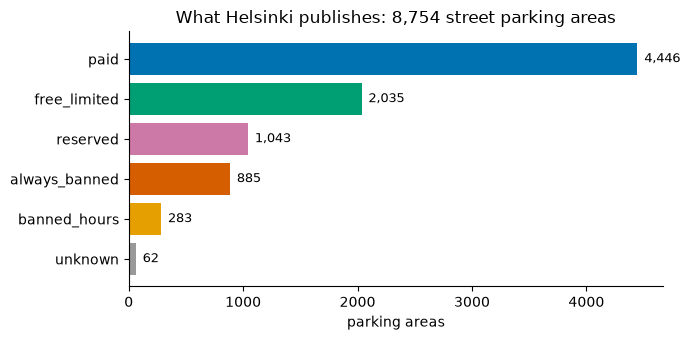

In [5]:
rs.plot_rule_types(areas);

Three quarters of street parking allows parking in some form. The remaining quarter, reserved and
banned, is where fines happen and is exactly what a driver cannot see from the car.

Reserved bays look like ordinary spaces from the driver's seat. What they are reserved for:

In [6]:
Markdown(rs.reserved_for(areas))

### Reserved areas by space type

| Reserved for          |   Areas |
|:----------------------|--------:|
| Electric scooter      |     312 |
| Electric car          |     187 |
| Taxi                  |     122 |
| Loading zone          |     100 |
| Accessible parking    |      88 |
| Tourist coach         |      63 |
| not stated            |      60 |
| Diplomatic vehicle    |      59 |
| Motorcycle            |      17 |
| Bicycle               |      14 |
| Taxi, charging        |       8 |
| Car or van            |       3 |
| Official vehicle      |       3 |
| Police                |       2 |
| City Executive Office |       1 |
| Mobile library        |       1 |
| Parklet               |       1 |
| Finnish Government    |       1 |
| Lorry                 |       1 |


## 4. Where the register is

Rule type against district, one bar per district. Bar length shows how much of the register is
there; the colours show what it says.

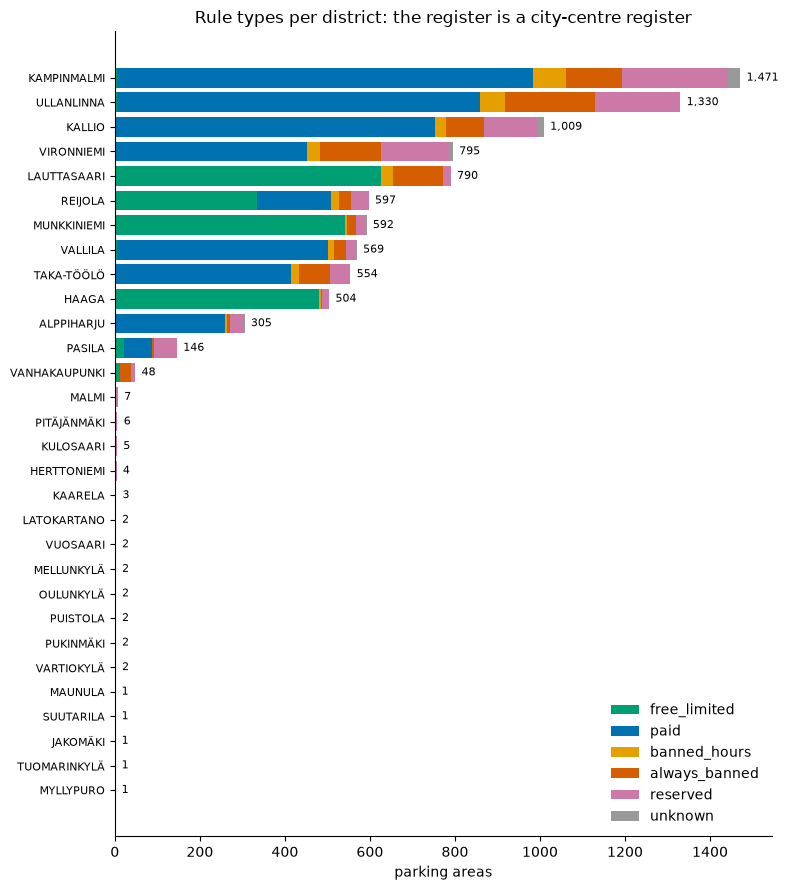

In [7]:
rs.plot_rule_type_by_district(areas);

Two findings.

**This is a city-centre register.** Kampinmalmi, Ullanlinna and Kallio hold more than 3,800 areas
between them, while 17 of the 30 districts have fewer than ten. The likely reason is that the city
does not regulate kerbside parking in the suburbs, so an empty map there probably means "no
rule", not "no data". Nothing in the register lets the app tell a driver which.

**Rule type clusters by district.** The centre is paid, while Lauttasaari, Munkkiniemi and Haaga
are almost entirely free with a time limit, the parking-disc districts. This matters for the
learning stage: validating by holding out a whole district also holds out a whole rule regime.

## 5. Time limits against rule type

In [8]:
Markdown(rs.duration_by_rule_type(areas))

### Time limit against rule type

| Time limit       |   always_banned |   banned_hours |   free_limited |   paid |   reserved |   unknown |
|:-----------------|----------------:|---------------:|---------------:|-------:|-----------:|----------:|
| none stated      |             883 |            281 |            372 |   3372 |        982 |        61 |
| no limit, stated |               0 |              0 |              0 |      0 |          7 |         0 |
| 15 min           |               0 |              0 |              5 |      0 |          5 |         0 |
| 30 min           |               0 |              0 |             16 |      3 |         17 |         0 |
| 1 h              |               0 |              1 |             27 |    457 |         13 |         0 |
| 2 h              |               0 |              1 |             20 |     84 |          6 |         0 |
| 4 h              |               2 |              0 |           1582 |    524 |          1 |         1 |
| 6 h              |               0 |              0 |              0 |      0 |          1 |         0 |
| 12 h             |               0 |              0 |              0 |      0 |          5 |         0 |
| 24 h             |               0 |              0 |             13 |      6 |          6 |         0 |


Limits are mostly where they should be: four hours on free-limited areas, one or four hours on
paid ones. But a crosstab also shows combinations that should not exist, which a check on a single
column never would. A ban should not have a time limit:

In [9]:
odd = areas["duration_min"].notna() & areas["rule_type"].isin(["always_banned", "banned_hours", "unknown"])
areas.loc[odd, ["id", "rule_type", "luokka", "tyyppi", "voimassaolo", "kesto", "status"]]

,id,rule_type,luokka,tyyppi,voimassaolo,kesto,status
348,8354,always_banned,NaN,Pysäköintikielto,8-20,4 h,official
426,8434,always_banned,NaN,Pysäköintikielto,,4,official
774,8822,banned_hours,9.0,,"11-16, (11-16), 11-16",2 h,official
1585,9646,banned_hours,9.0,,9-17,60 min,official
8671,16971,unknown,NaN,8,6-24,4 h,uncertain


And the reverse: an area the app treats as complete, free with a time limit, but with no limit
stated. For a parking disc there always is one.

In [10]:
silent = ((areas["rule_type"] == "free_limited") & areas["duration_min"].isna()
          & (areas["status"] == "official"))
areas.loc[silent, ["id", "luokka", "class_name_en", "voimassaolo", "kesto"]]

,id,luokka,class_name_en,voimassaolo,kesto
8104,16390,8.0,Free short-term parking without a permit; use ...,8-20,


These are register errors, not parsing errors: the city's own record contradicts itself. Both
cases are raised as open questions on the board (`docs/TODO.md`), because the fix is a decision
about what the app should say, not about the data.

## 6. Outliers in polygon size

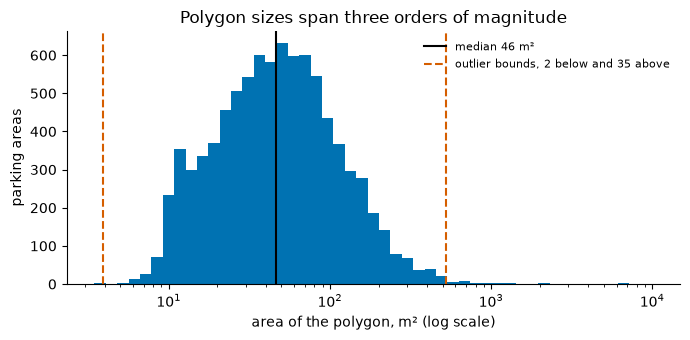

In [11]:
rs.plot_area_sizes(areas);

Sizes span three orders of magnitude, from a few square metres to almost a hectare. So the
outlier rule (1.5 times the interquartile range beyond the quartiles) is applied to the
**logarithm** of the area: on the raw scale every large polygon would be an outlier and no small
one could be.

In [12]:
Markdown(rs.area_outliers(areas))

### Area sizes and outliers

| Measure               | Value         |
|:----------------------|:--------------|
| Median area           | 46 m²         |
| Smallest              | 3.5 m²        |
| Largest               | 9,977 m²      |
| Outlier bounds        | 3.9 to 527 m² |
| Below the lower bound | 2             |
| Above the upper bound | 35            |

### The smallest outliers and the five largest areas

|    Id | Rule type     | Space type   | District    |   Area, m² |
|------:|:--------------|:-------------|:------------|-----------:|
| 16661 | always_banned | No parking   | LAUTTASAARI |        3.5 |
| 16673 | always_banned | No parking   | LAUTTASAARI |        3.9 |
| 16732 | always_banned | No parking   | TAKA-TÖÖLÖ  |     9977.4 |
| 16606 | always_banned | No parking   | KALLIO      |     7093.6 |
| 16585 | always_banned | No parking   | ULLANLINNA  |     6743.4 |
| 16607 | always_banned | No parking   | KALLIO      |     2549.7 |
| 17035 | always_banned | No parking   | KALLIO      |     2167.1 |

13 of the 35 large outliers overlap another area, 31 areas in all.


The largest polygons are not street sections at all but whole no-parking squares. What matters
is where one lies over a street section, because on the map a tap there can select the zone
instead of the section the driver meant. The large polygon that overlaps the most areas:

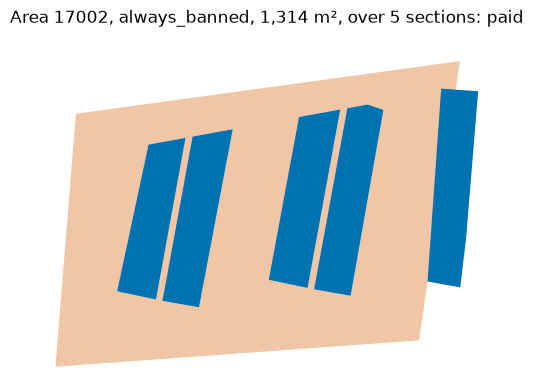

In [13]:
large, overlaps = rs.large_overlaps(areas)
zone_id = overlaps["id_right"].value_counts().index[0]
zone = areas[areas["id"] == zone_id]
under = areas[areas["id"].isin(overlaps.loc[overlaps["id_right"] == zone_id, "id_left"])]

ax = zone.plot(color=rs.RULE_COLOURS[zone["rule_type"].iloc[0]], alpha=0.35, figsize=(6, 6))
under.plot(ax=ax, color=[rs.RULE_COLOURS[r] for r in under["rule_type"]])
ax.set_title(f"Area {zone_id}, {zone['rule_type'].iloc[0]}, {zone.area.iloc[0]:,.0f} m², "
             f"over {len(under)} sections: {', '.join(sorted(under['rule_type'].unique()))}")
ax.set_axis_off();

Most likely the paid bays are exceptions inside a no-parking square, so where polygons overlap,
the smaller one is the rule that applies. The app currently selects whichever polygon is drawn
on top. How to handle it is an open question on the board.

## 7. What the app can answer

The status preprocessing gave each area decides what the app can say there.

In [14]:
Markdown(rs.coverage(areas))

### What the app can answer

| Status                          |   Areas |
|:--------------------------------|--------:|
| Complete rule published         |    7391 |
| Rule type known, hours missing  |     978 |
| Uncertain, with a stated reason |     385 |


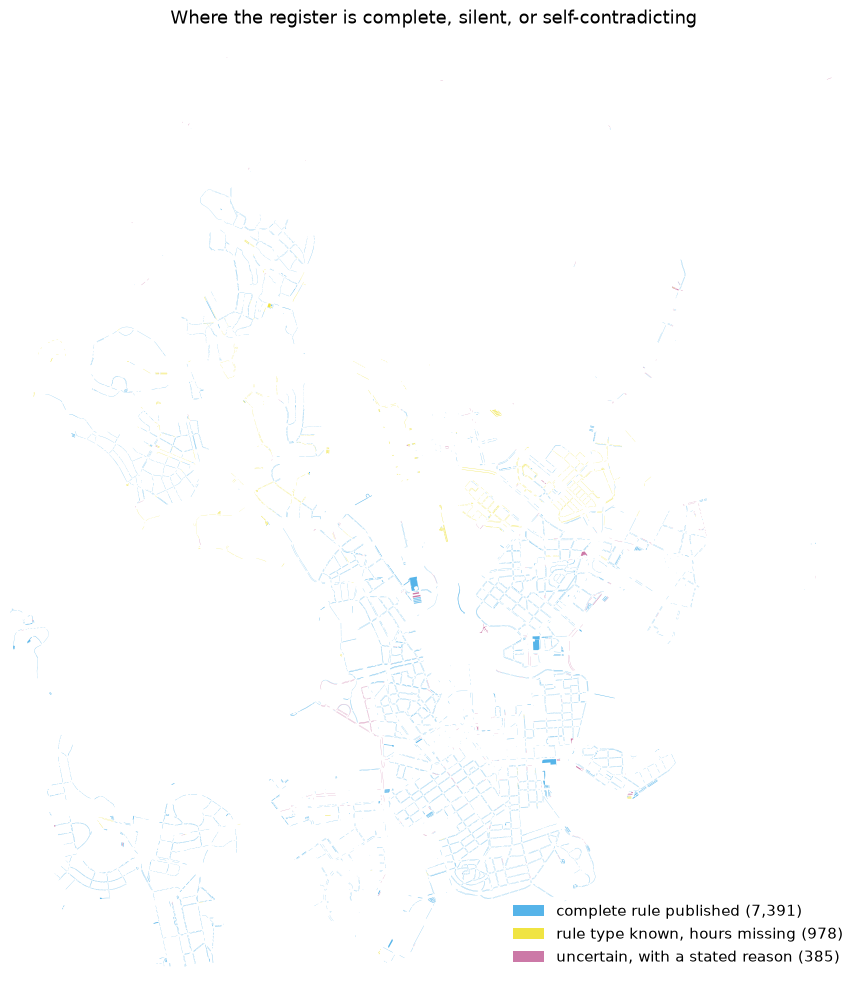

In [15]:
rs.plot_status_map(areas);

The gaps are not spread evenly; they sit mostly outside the centre, which matters for who a
prediction can help.

## 8. Can neighbours predict the missing hours?

This is the experiment that chose the learning method. Take every area whose hours we know, hide
them, copy the hours of its nearest neighbour, and count how often the copy is right. "Nearest"
uses a spatial index (`sjoin_nearest`), so it runs over every area, not a sample.

In [16]:
paired = rs.nearest_pairs(known)
baseline = rs.baseline_accuracy(known)
by_dist = rs.accuracy_by_distance(paired)
Markdown(rs.neighbour_accuracy(paired, by_dist, baseline))

Copying the nearest same-class area is correct **97.5%** of the time, over 5,834 comparisons. Always guessing the most common pattern scores **32.9%**.

### Accuracy by distance

| Distance to nearest same-class area   |   Correct |   Areas |
|:--------------------------------------|----------:|--------:|
| 0-10 m                                |      99.5 |    4711 |
| 10-50 m                               |      95.5 |     706 |
| 50-200 m                              |      68.4 |     152 |
| over 200 m                            |      35.4 |      65 |


**Why the same class?** The neighbour is taken from areas of the same parking class. Allowing any
neighbour does worse: a paid section and the loading bay next to it, for example, need not share
hours.

In [17]:
any_class = rs.nearest_pairs(known, same_class=False)
pd.Series({"same class": paired["match"].mean(), "any class": any_class["match"].mean()},
          name="hours copied correctly, %").mul(100).round(1)

same class    97.5
any class     88.9
Name: hours copied correctly, %, dtype: float64

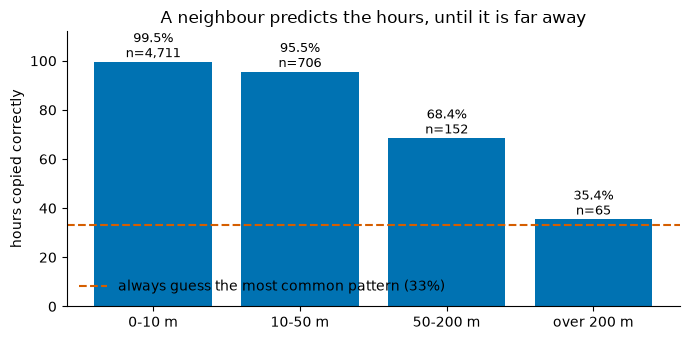

In [18]:
rs.plot_accuracy_by_distance(by_dist, baseline);

**The catch.** Accuracy depends almost entirely on distance. The areas we actually need to
predict sit much further from a known area than the areas we measured on:

In [19]:
Markdown(rs.prediction_gap(areas, known))

### Distance from a missing-hours area to the nearest area we can learn from

| Measure         | Value   |
|:----------------|:--------|
| Areas measured  | 978     |
| Median distance | 153 m   |
| Within 10 m     | 3.8%    |
| Within 50 m     | 17.7%   |
| Within 200 m    | 57.4%   |


So the 97.5% headline describes areas we do not need to predict. Where we do, the nearest
known area is a median of about 150 m away, where copying is right far less often. The honest
expectation is a confident answer for some of the 978 areas and "unknown" for the rest.

## 9. What this stage hands on

- **To learning (stage 5):** the method, same-class nearest neighbours; the baseline to beat,
  32.9%; an honest expectation, judged at the distances we will really face rather than the
  97.5% headline; and a validation split, by district, that also holds out a rule regime.
- **To the app (stage 6):** large no-parking polygons that overlap street sections, and a
  free-limited area with no stated limit. Both are open questions on the board.
- **To the report:** the same tables and figures, generated by `report_stats.py` into
  `docs/report_stats.md` and `docs/figures/`.